In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("smartcart_customers.csv")

In [3]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,172,88,88,3,8,10,4,7,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,2,1,6,2,1,1,2,5,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,111,21,42,1,8,2,10,4,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,10,3,5,2,2,0,4,6,0,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,46,27,15,5,5,3,6,5,0,0


In [4]:
df.shape

(2240, 22)

In [5]:
df.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
Complain                0
Response                0
dtype: int64

# Data Preprocessing

In [6]:
# Handle missing values
df["Income"]=df["Income"].fillna(df["Income"].median())

In [8]:
# Feature Engineering
# Convert birth year into age
df["Age"]=2026-df["Year_Birth"]

In [10]:
#Customer joining date
df["Dt_Customer"]= pd.to_datetime(df["Dt_Customer"],dayfirst=True)
ref_date=df["Dt_Customer"].max()
df["Customer_Tenure_Days"]=(ref_date-df["Dt_Customer"]).dt.days

In [12]:
#Total spending
df["Total_Spending"]=df["MntWines"]+df["MntFruits"]+df["MntMeatProducts"]+df["MntFishProducts"]
+df["MntSweetProducts"]+df["MntGoldProds"]

0       176
1         7
2        63
3         8
4        42
       ... 
2235    365
2236      8
2237     36
2238     91
2239     22
Length: 2240, dtype: int64

In [85]:
#Total children
df["Total_Children"]=df["Kidhome"]+df["Teenhome"]
df=df.drop(columns=["Total_children"],axis=1)

In [86]:
#Education
df["Education"].value_counts()
df["Education"]=df["Education"].replace({
    "Basic":"Undergraduate","2n Cycle":"Undergraduate",
    "Graduation":"Graduate",
    "Master":"Postgraduate",
    "PhD":"Postgraduate"
})

In [87]:
# Marital status
df["Marital_Status"].value_counts()
df["Living_With"]=df["Marital_Status"].replace({
    "Married":"Partner","Together":"Partner",
    "Single":"Alone",
    "Divorced":"Alone",
    "Widow":"Alone",
    "Absurd":"Alone",
    "YOLO":"Alone"
})

In [88]:
df["Living_With"].value_counts()

Living_With
Partner    1444
Alone       796
Name: count, dtype: int64

In [89]:
df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Living_With,Total_Children
0,5524,1957,Graduate,Alone,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,1,69,663,1441,Alone,0
1,2174,1954,Graduate,Alone,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,72,113,20,Alone,2
2,4141,1965,Graduate,Partner,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,61,312,713,Partner,0
3,6182,1984,Graduate,Partner,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,42,139,45,Partner,1
4,5324,1981,Postgraduate,Partner,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,45,161,380,Partner,1


In [90]:
# Drop Columns
cols=["ID","Year_Birth","Marital_Status","Kidhome","Teenhome","Dt_Customer"]
spending_cols=["MntWines","MntFruits","MntMeatProducts","MntFishProducts","MntSweetProducts","MntGoldProds"]
cols_to_drop=cols+spending_cols
df_cleaned=df.drop(columns=cols_to_drop)

In [91]:
df_cleaned.shape

(2240, 15)

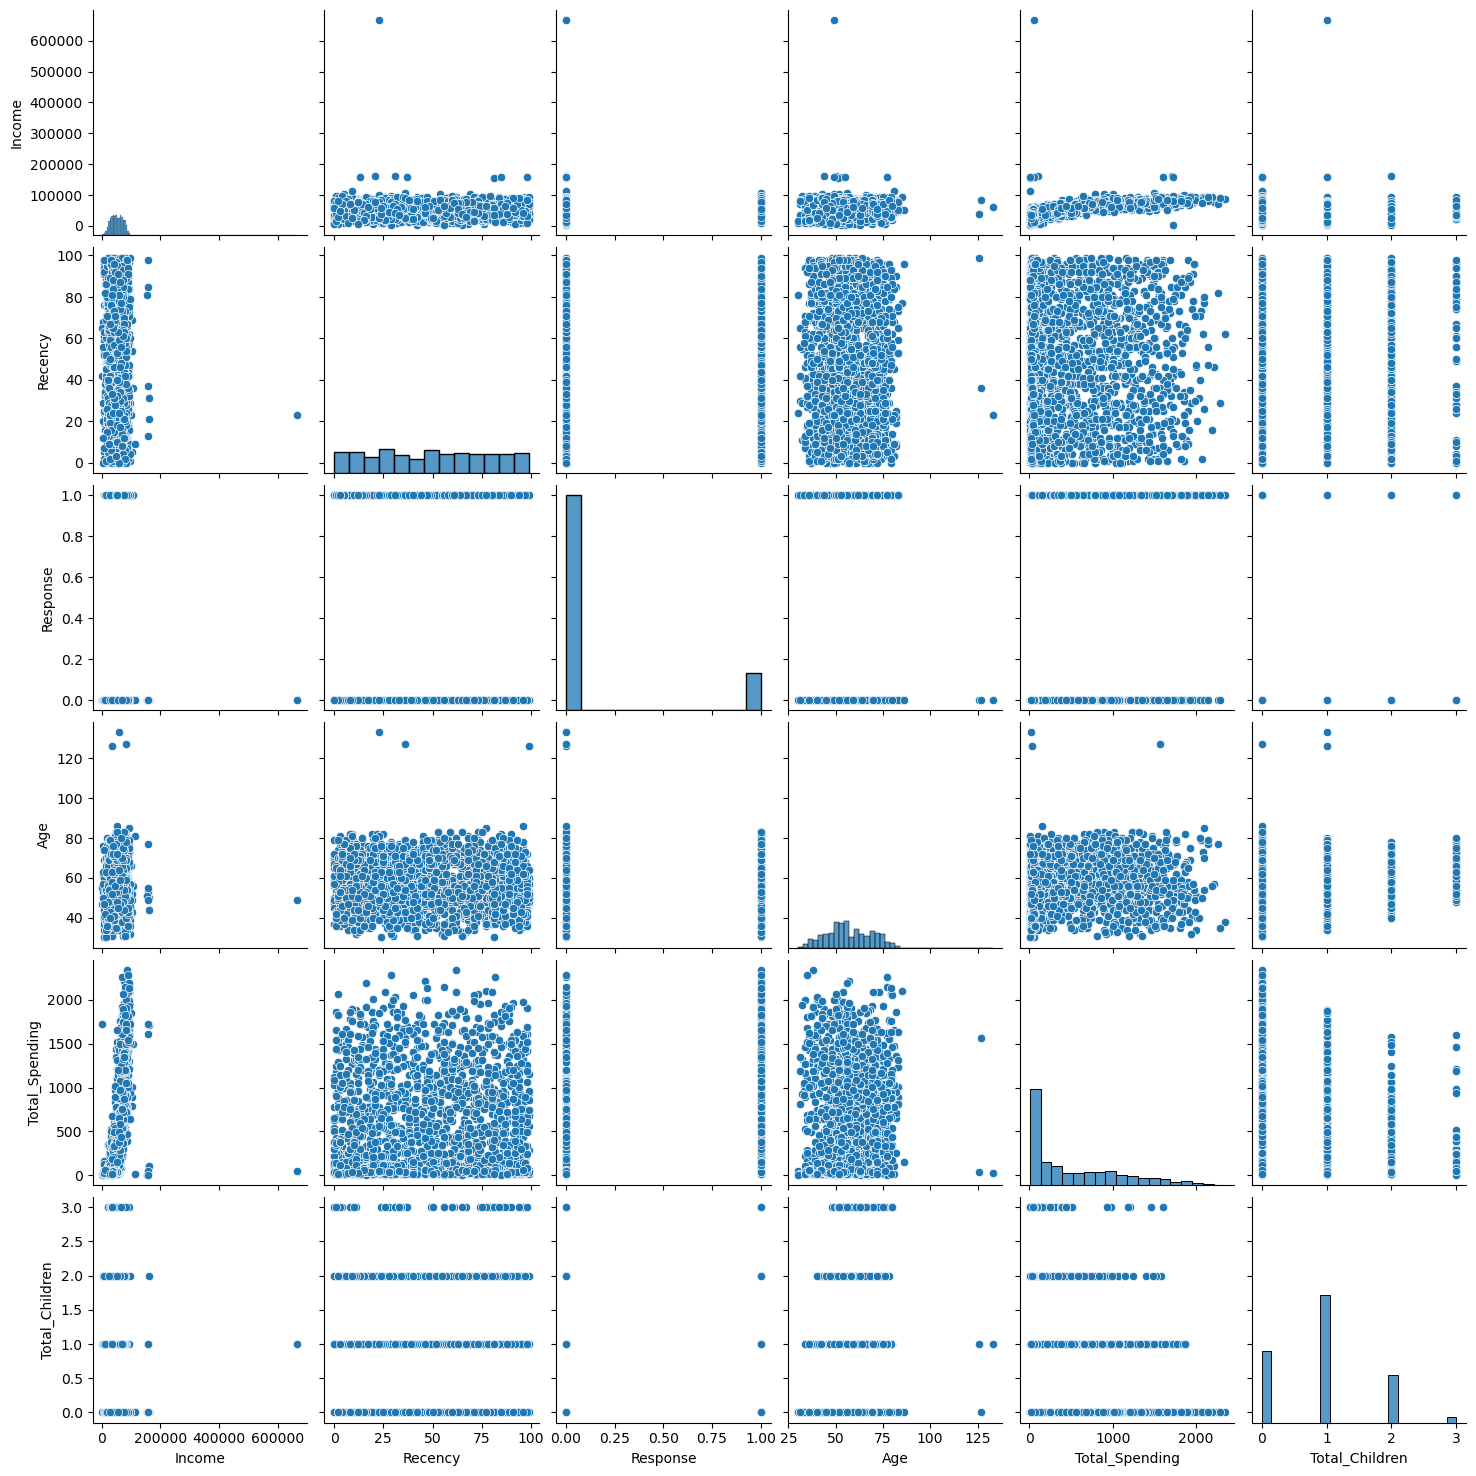

In [92]:
#Outliers
cols=["Income","Recency","Response","Age","Total_Spending","Total_Children"]
#relative plots of some features-pair plots
sns.pairplot(df_cleaned[cols])

In [93]:
# Remove Outliers
print("data size with outliers",len(df_cleaned))
df_cleaned=df_cleaned[(df_cleaned["Age"]<90)]
df_cleaned=df_cleaned[(df_cleaned["Income"]<600000)]
print("data size without outliers",len(df_cleaned))


data size with outliers 2240
data size without outliers 2236


In [94]:
# Correlation Matrix
corr=df_cleaned.corr(numeric_only=True)

<Axes: >

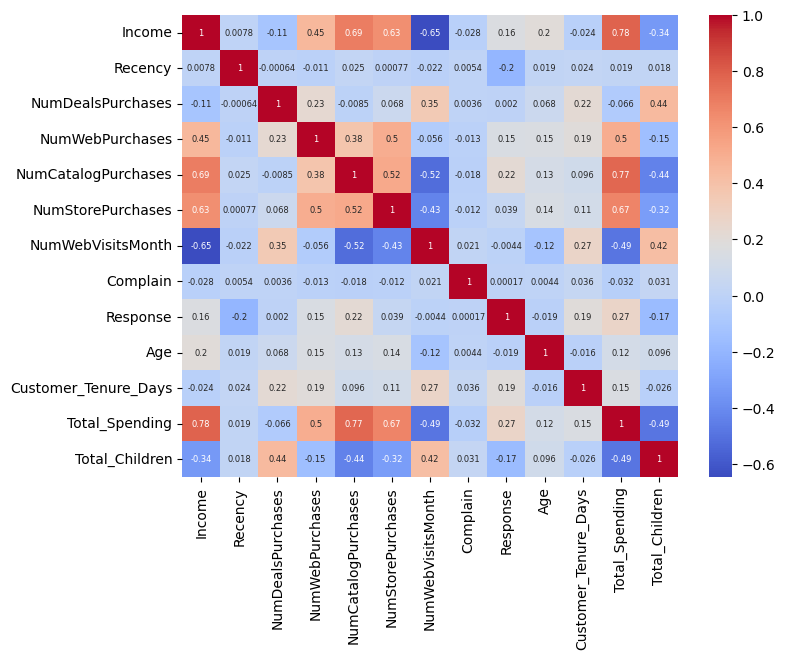

In [95]:
plt.figure(figsize=(8,6))
sns.heatmap(
    corr,
    annot=True,
    annot_kws={"size":6},
    cmap="coolwarm"
)

In [96]:
# Feature Encoding - One Hot Encoding
from sklearn.preprocessing import OneHotEncoder
ohe=OneHotEncoder()
cat_cols=["Education","Living_With"]
enc_cols=ohe.fit_transform(df_cleaned[cat_cols])

In [97]:
enc_df=pd.DataFrame(enc_cols.toarray(),columns=ohe.get_feature_names_out(cat_cols),index=df_cleaned.index)

In [98]:
enc_df.head()

,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,1.0,0.0,0.0,1.0,0.0
1,1.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,1.0


In [99]:
df_encoded=pd.concat([df_cleaned.drop(columns=cat_cols),enc_df],axis=1)

In [100]:
df_encoded.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner
0,58138.0,58,3,8,10,4,7,0,1,69,663,1441,0,1.0,0.0,0.0,1.0,0.0
1,46344.0,38,2,1,1,2,5,0,0,72,113,20,2,1.0,0.0,0.0,1.0,0.0
2,71613.0,26,1,8,2,10,4,0,0,61,312,713,0,1.0,0.0,0.0,0.0,1.0
3,26646.0,26,2,2,0,4,6,0,0,42,139,45,1,1.0,0.0,0.0,0.0,1.0
4,58293.0,94,5,5,3,6,5,0,0,45,161,380,1,0.0,1.0,0.0,0.0,1.0


In [101]:
X=df_encoded

In [102]:
# Scaling Data
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

# Visualization

In [103]:
X_scaled.shape

(2236, 18)

In [108]:
from sklearn.decomposition import PCA
pca=PCA(n_components=3)
X_pca=pca.fit_transform(X_scaled)


In [109]:
pca.explained_variance_ratio_

array([0.23071677, 0.11385898, 0.10411053])

Text(0.5, 0.92, '3D Projections')

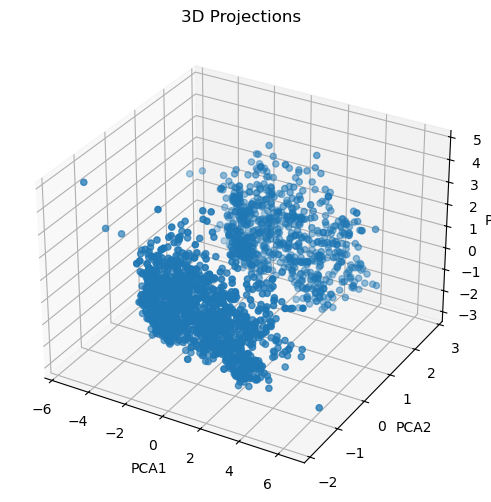

In [112]:
# Plot
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2])
ax.set_xlabel("PCA1")
ax.set_ylabel("PCA2")
ax.set_zlabel("PCA3")
ax.set_title("3D Projections")

# Analyse K Value

In [114]:
from sklearn.cluster import KMeans
from kneed import KneeLocator

In [115]:
wcss=[]
for k in range(1,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    kmeans.fit_predict(X_pca)
    wcss.append(kmeans.inertia_)

In [116]:
knee=KneeLocator(range(1,11),wcss,curve="convex",direction="decreasing")
optimal_k=knee.elbow

In [117]:
print("best k=",optimal_k)

best k= 4


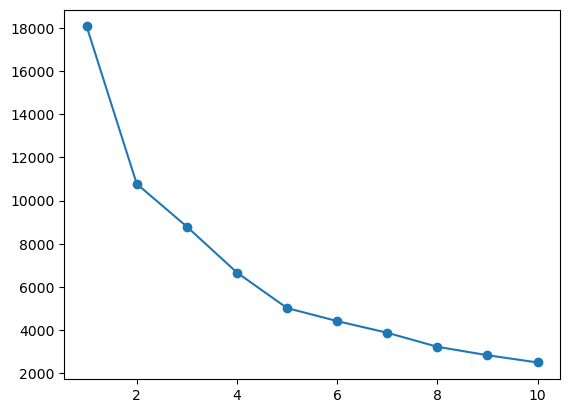

In [118]:
# Plot
plt.plot(range(1,11),wcss,marker='o')

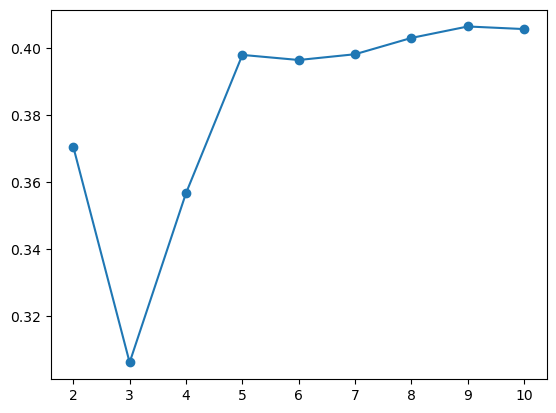

In [119]:
# Silhouette Score
from sklearn.metrics import silhouette_score
scores=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,random_state=42)
    labels=kmeans.fit_predict(X_pca)
    score=silhouette_score(X_pca,labels)
    scores.append(score)
#plot
plt.plot(range(2,11),scores,marker='o')

# Clustering

In [120]:
# KMeans
kmeans=KMeans(n_clusters=4,random_state=42)
labels_kmeans=kmeans.fit_predict(X_pca)

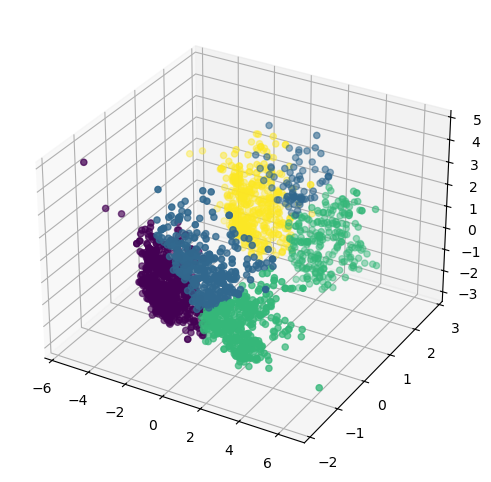

In [121]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=labels_kmeans)


In [123]:
# Agglomerative
from sklearn.cluster import AgglomerativeClustering

In [124]:
agg_clf=AgglomerativeClustering(n_clusters=4,linkage="ward")
labels_agg=agg_clf.fit_predict(X_pca)

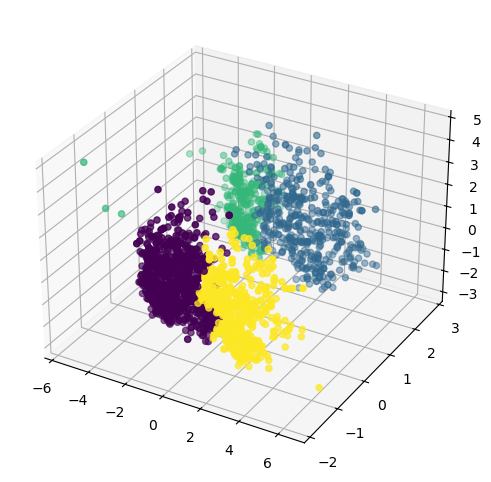

In [125]:
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(111,projection="3d")
ax.scatter(X_pca[:,0],X_pca[:,1],X_pca[:,2],c=labels_agg)

# Characterization of Clusters

In [141]:
X["clusters"]=labels_agg

In [142]:
X.head()

,Income,Recency,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Complain,Response,Age,Customer_Tenure_Days,Total_Spending,Total_Children,Education_Graduate,Education_Postgraduate,Education_Undergraduate,Living_With_Alone,Living_With_Partner,clusters
0,58138.0,58,3,8,10,4,7,0,1,69,663,1441,0,1.0,0.0,0.0,1.0,0.0,1
1,46344.0,38,2,1,1,2,5,0,0,72,113,20,2,1.0,0.0,0.0,1.0,0.0,2
2,71613.0,26,1,8,2,10,4,0,0,61,312,713,0,1.0,0.0,0.0,0.0,1.0,3
3,26646.0,26,2,2,0,4,6,0,0,42,139,45,1,1.0,0.0,0.0,0.0,1.0,0
4,58293.0,94,5,5,3,6,5,0,0,45,161,380,1,0.0,1.0,0.0,0.0,1.0,0


<Axes: xlabel='clusters', ylabel='count'>

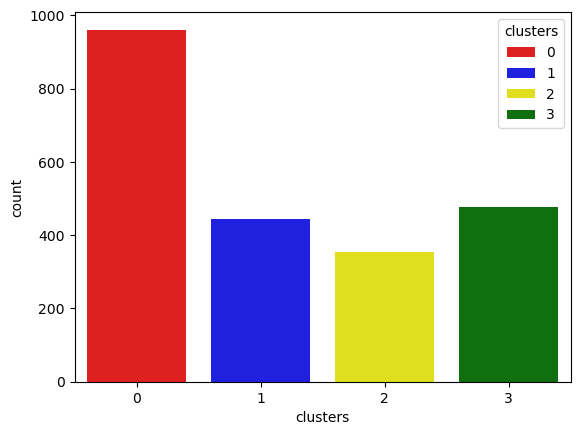

In [143]:
pal=["red","blue","yellow","green"]
sns.countplot(x=df_cleaned["clusters"],palette=pal,hue=df_cleaned["clusters"])

<Axes: xlabel='Total_Spending', ylabel='Income'>

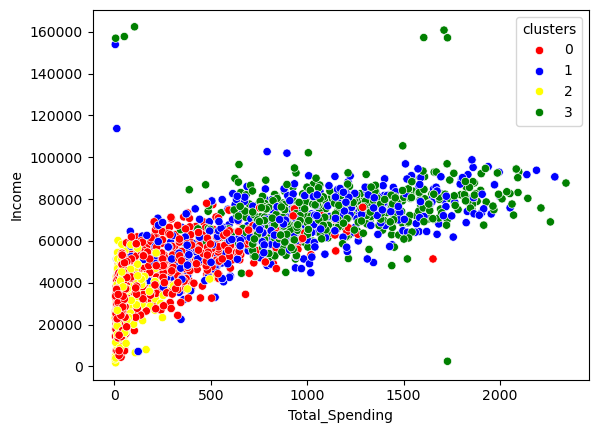

In [144]:
# Income and spending patterns
sns.scatterplot(x=X["Total_Spending"],y=X["Income"],hue=X["clusters"],palette=pal)

In [146]:
# Cluster Summary
cluster_summary=X.groupby("clusters").mean()
print(cluster_summary)

                Income    Recency  NumDealsPurchases  NumWebPurchases  \
clusters                                                                
0         40965.757544  49.332986           2.633715         3.290323   
1         66681.390766  50.198198           2.218468         5.610360   
2         33339.582153  48.141643           2.328612         2.147309   
3         74105.736402  48.395397           1.805439         5.709205   

          NumCatalogPurchases  NumStorePurchases  NumWebVisitsMonth  Complain  \
clusters                                                                        
0                    1.104058           4.374610           6.238293  0.010406   
1                    4.398649           7.900901           4.209459  0.004505   
2                    0.535411           3.050992           6.810198  0.014164   
3                    5.757322           8.723849           3.399582  0.006276   

          Response        Age  Customer_Tenure_Days  Total_Spending  \
clu